# 🤖 PENGEMBANGAN MODEL CHATBOT PEMANDU BELAJAR SOKRATIK (PyJourney)
### Domain Adaptation & Fine-Tuning Sentence-Transformers (Dense Semantic Embeddings)
---
**Program Studi:** S-1 Teknik Informatika  
**Fakultas:** Teknik dan Ilmu Komputer (FTIK) - Universitas Nusantara PGRI Kediri  
**Peneliti / Penulis:** Ananda Salwa Pratama (NIM 2313020125)  
**Fokus Tugas Akhir (R&D):** *Asisten Belajar Interaktif Pemrograman Python Menggunakan Physical Socratic Companion (ESP32-S3) dan Validasi AST Sandbox*  

---
### 📌 Latar Belakang & Urgensi Ilmiah Fine-Tuning
Pada tahap penelitian awal (`chatbot-pemandu.ipynb`), mesin temu kembali semantik menggunakan model *pre-trained* `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2` secara langsung (*Zero-Shot*). Meskipun model tersebut telah dilatih pada miliaran korpus teks umum, terdapat kesenjangan pemahaman semantik (*domain semantic gap*) saat berhadapan dengan:
1. **Terminologi & Jargon Pemrograman Spesifik:** Istilah teknis seperti *docstring*, *ternary operator*, *slicing*, *keyword arguments*, atau *modulo*.
2. **Leksikon Informal & Slang Mahasiswa:** Pertanyaan awam seperti *"pembagian garing dua"*, *"sisa bagi modulo operatornya apa ya bro"*, atau *"cara nulis percabangan ringkas satu baris"*.
3. **Karakteristik Pertanyaan Berbasis Gejala / Error:** Mahasiswa sering mengeluhkan *"IndentationError"* atau *"program macet looping tak henti"* tanpa mengetahui bab/konsep apa yang salah.

Untuk mengatasi masalah tersebut, notebook ini mengimplementasikan **Domain Adaptation (Fine-Tuning) Sentence-Transformers** menggunakan kerangka *Contrastive Learning* dengan `MultipleNegativesRankingLoss` (MNRL):
- **Sintesis Variasi Kueri Latih (225 Pertanyaan):** Memetakan 15 Episode konsep mikro pada 5 Bab kurikulum resmi CPython dengan berbagai ragam bahasa.
- **Pemisahan Data Uji Objektif (35 Benchmark Queries):** 35 skenario kueri riil disimpan secara ketat sebagai *unseen test set* untuk menguji daya generalisasi model.
- **Evaluasi Ilmiah Sebelum vs Sesudah Fine-Tuning:** Mengukur metrik standar *Information Retrieval* (*Top-1, Top-3, Top-5 Accuracy*, dan *MRR*) untuk membuktikan peningkatan performa secara empiris bagi Bab 4 Skripsi.


## 1. Setup Lingkungan & Import Dependensi
Pustaka utama yang digunakan:
- `sentence-transformers` & `torch`: Arsitektur Transformer untuk pelatihan representasi vektor semantik kalimat (*dense embeddings*).
- `MultipleNegativesRankingLoss`: Fungsi kerugian contrastive ranking untuk fine-tuning pencarian informasi.
- `beautifulsoup4 (bs4)`: Ekstraksi dan sanitasi teks bersih dari markup HTML dokumen resmi Sphinx CPython.
- `pandas` & `numpy`: Manajemen struktur data korpus tabular dan komputasi aljabar matriks kesamaan kosinus.
- `matplotlib`: Visualisasi grafik komparasi performa sebelum vs sesudah *fine-tuning* untuk pelaporan naskah skripsi.


In [26]:
import os
import re
import json
import random
import time
from pathlib import Path
from bs4 import BeautifulSoup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sentence_transformers import SentenceTransformer, InputExample, util
from sentence_transformers.sentence_transformer.losses import MultipleNegativesRankingLoss
from torch.utils.data import DataLoader

# Tetapkan random seed agar seluruh eksperimen dapat direproduksi secara konsisten
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# Konfigurasi direktori dataset dan artefak keluaran
BASE_DIR = Path.cwd().parent
DATASET_DIR = BASE_DIR / "dataset"
CHAPTERS_DIR = DATASET_DIR / "generated" / "chapters"
CURRICULUM_PATH = DATASET_DIR / "curriculum.json"
OUTPUT_DIR = Path.cwd() / "output_artifacts"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"[STATUS] Komputasi berjalan pada perangkat: {device.upper()}")
print(f"[STATUS] Direktori Bab Materi: {CHAPTERS_DIR.resolve()}")
print(f"[STATUS] File Kurikulum: {CURRICULUM_PATH.resolve()} (Tersedia: {CURRICULUM_PATH.exists()})")
print(f"[STATUS] Direktori Artefak Ekspor: {OUTPUT_DIR.resolve()}")


[STATUS] Komputasi berjalan pada perangkat: CPU
[STATUS] Direktori Bab Materi: /media/pratama/Data/Other/SELURUH FILE PERKULIAHAN/SKRIPSI/projek2/training-model/dataset/generated/chapters
[STATUS] File Kurikulum: /media/pratama/Data/Other/SELURUH FILE PERKULIAHAN/SKRIPSI/projek2/training-model/dataset/curriculum.json (Tersedia: True)
[STATUS] Direktori Artefak Ekspor: /media/pratama/Data/Other/SELURUH FILE PERKULIAHAN/SKRIPSI/projek2/training-model/train/output_artifacts


## 2. Eksplorasi Korpus & Analisis Noise Teks HTML
Materi pembelajaran bersumber dari dokumentasi resmi CPython yang di-generate via Sphinx JSON builder.
Blok-blok materi mentah memuat noise berupa tag HTML (`<a href>`, `<code>`, `<div>`, dll.) yang harus disanitasi sebelum dimasukkan ke dalam model NLP.


In [27]:
# Inspeksi sampel teks mentah dari dataset materi bab fungsi
sample_file = CHAPTERS_DIR / "fungsi.json"
with open(sample_file, "r", encoding="utf-8") as f:
    sample_data = json.load(f)

sample_raw_html = sample_data["groups"][0]["blocks"][33]["html"]
print("=== CONTOH TEKS MENTAH DARI DATASET JSON ===")
print(sample_raw_html)
print("=" * 50)


=== CONTOH TEKS MENTAH DARI DATASET JSON ===
Fungsi juga dapat dipanggil menggunakan <a href="https://docs.python.org/3.13/glossary.html#term-keyword-argument" rel="noopener noreferrer" target="_blank">argumen kata kunci (keyword arguments)</a>
dalam bentuk <code>kwarg=value</code>. Sebagai contoh, fungsi berikut:


## 3. Preprocessing Pipeline & Sanitasi Teks HTML
Tahapan pembersihan teks mentah:
1. **Ekstraksi Teks Murni:** Membersihkan tag HTML menggunakan `BeautifulSoup` dengan pemisah spasi alami.
2. **Preservasi Entitas Kode:** Mempertahankan token sintaksis pemrograman di dalam tag `<code>`.
3. **Penyelamatan Metadata URL:** Mengekstrak tautan rujukan eksternal (`<a href>`) ke dalam list referensi terpisah.


In [28]:
def clean_html_content(raw_html: str) -> tuple[str, list[str]]:
    """
    Membersihkan teks HTML dokumentasi menjadi teks murni untuk input NLP,
    sekaligus mengekstraksi daftar URL rujukan jika tersedia.
    """
    if not raw_html or not isinstance(raw_html, str):
        return "", []

    soup = BeautifulSoup(raw_html, "html.parser")

    # 1. Kumpulkan tautan resmi dari tag <a href>
    links = []
    for a_tag in soup.find_all("a", href=True):
        href = a_tag.get("href", "").strip()
        if href and href.startswith("http"):
            links.append(href)

    # 2. Ambil teks murni dengan pemisah spasi
    clean_text = soup.get_text(separator=" ", strip=True)

    # 3. Normalisasi spasi dan karakter baris baru berlebih
    clean_text = re.sub(r'\s+', ' ', clean_text).strip()

    return clean_text, list(dict.fromkeys(links))

# Uji coba fungsi pembersih pada sampel HTML
cleaned_text, extracted_urls = clean_html_content(sample_raw_html)
print("=== HASIL SANITASI & PREPROCESSING NLP ===")
print("Teks Bersih    :", cleaned_text)
print("URL Referensi  :", extracted_urls)
print("=" * 50)


=== HASIL SANITASI & PREPROCESSING NLP ===
Teks Bersih    : Fungsi juga dapat dipanggil menggunakan argumen kata kunci (keyword arguments) dalam bentuk kwarg=value . Sebagai contoh, fungsi berikut:
URL Referensi  : ['https://docs.python.org/3.13/glossary.html#term-keyword-argument']


## 4. Ekstraksi Korpus & Concept-Level Chunking
Seluruh materi diekstraksi dan dipartisi menjadi unit pengetahuan (*knowledge passages*) berukuran granular yang dipetakan secara proporsional ke dalam 3 Episode per Bab:
- `chapter_order`: Urutan Bab (1 - 5).
- `chapter_slug`: Slug identitas Bab.
- `chapter_title`: Judul Bab resmi.
- `episode_id`: ID Episode konsep mikro (15 Episode total).
- `episode_title`: Judul Episode.
- `concept`: Ringkasan konsep yang dipelajari.
- `passage_text`: Konten teks penjelasan materi bersih.
- `source_urls`: Tautan ke dokumentasi resmi Python CPython.


In [29]:
# Baca struktur kurikulum resmi
with open(CURRICULUM_PATH, "r", encoding="utf-8") as f:
    curriculum_meta = json.load(f)

curriculum_lookup = {ch["slug"]: ch for ch in curriculum_meta["chapters"]}

corpus_records = []
total_blocks_processed = 0

for chapter_file in sorted(CHAPTERS_DIR.glob("*.json")):
    slug = chapter_file.stem
    if slug not in curriculum_lookup:
        continue

    ch_info = curriculum_lookup[slug]
    order = ch_info["order"]
    ch_title = ch_info["title"]
    episodes = ch_info.get("episodes", [])

    with open(chapter_file, "r", encoding="utf-8") as f:
        ch_data = json.load(f)

    groups = ch_data.get("groups", [])
    num_episodes = max(1, len(episodes))

    # Ekstraksi blok teks materi
    all_cleaned_blocks = []
    for g_idx, group in enumerate(groups):
        for b_idx, block in enumerate(group.get("blocks", [])):
            total_blocks_processed += 1
            raw_html = block.get("html", "")
            clean_t, urls = clean_html_content(raw_html)
            # Filter blok substansial (> 30 karakter dan bukan command prompt)
            if len(clean_t) >= 30 and not clean_t.startswith(">>> "):
                all_cleaned_blocks.append({"text": clean_t, "urls": urls})

    # Petakan blok materi ke dalam episode proporsional
    chunk_size = max(1, len(all_cleaned_blocks) // num_episodes)
    for ep_idx, ep in enumerate(episodes):
        start_i = ep_idx * chunk_size
        end_i = (ep_idx + 1) * chunk_size if ep_idx < num_episodes - 1 else len(all_cleaned_blocks)
        ep_blocks = all_cleaned_blocks[start_i:end_i]

        for b_item in ep_blocks:
            corpus_records.append({
                "chapter_order": order,
                "chapter_slug": slug,
                "chapter_title": ch_title,
                "episode_id": ep["id"],
                "episode_title": ep["title"],
                "concept": ep["concept"],
                "passage_text": b_item["text"],
                "source_urls": b_item["urls"]
            })

df_corpus = pd.DataFrame(corpus_records)
print(f"[STATUS] Berhasil memproses {total_blocks_processed} blok teks mentah.")
print(f"[STATUS] Total Passage Korpus Pengetahuan Terekstraksi: {len(df_corpus)} dokumen.")
print("\nDistribusi Dokumen per Bab:")
print(df_corpus["chapter_title"].value_counts().to_string())


[STATUS] Berhasil memproses 476 blok teks mentah.
[STATUS] Total Passage Korpus Pengetahuan Terekstraksi: 303 dokumen.

Distribusi Dokumen per Bab:
chapter_title
Fungsi dengan def               92
Variabel & Tipe Data            66
List & Dictionary               63
Percabangan if / elif / else    44
Perulangan for & while          38


## 5. Sintesis Variasi Kueri Latih (Domain-Specific Synthetic Query Generation) & Data Uji Unseen
Dalam kaidah ilmiah penelitian *Information Retrieval*:
- **Data Latih (Training Set):** Membutuhkan jumlah pasangan $(q, p)$ yang cukup (ratusan sampel) agar model tidak *overfitting*. Kita membangun **225 kueri sintetis** (15 kueri per episode $\times$ 15 episode) yang mencakup pertanyaan sintaksis, istilah awam, slang informal, dan studi kasus error.
- **Data Uji (Test Set / Benchmark):** **35 kueri mahasiswa asli** disimpan secara murni (*unseen test data*). Model **sama sekali tidak dilatih** pada 35 kueri ini sehingga hasil evaluasi perbandingan benar-benar mencerminkan kemampuan generalisasi model terhadap pertanyaan baru.


In [30]:
# 1. Dataset 35 Kueri Benchmark (Data Uji Unseen - Ground Truth Akademik)
benchmark_queries = [
    # Bab 1: Variabel & Tipe Data
    {"query": "Bagaimana cara mengubah teks angka menjadi integer di python?", "target_slug": "variabel-dan-tipe-data", "target_ep": "ep-1-bilangan"},
    {"query": "Apa bedanya pembagian garing satu dengan garing dua di python?", "target_slug": "variabel-dan-tipe-data", "target_ep": "ep-1-bilangan"},
    {"query": "Gimana cara ngambil 3 huruf pertama dari sebuah string?", "target_slug": "variabel-dan-tipe-data", "target_ep": "ep-2-string"},
    {"query": "Fungsi apa yang dipakai untuk menghitung panjang karakter string?", "target_slug": "variabel-dan-tipe-data", "target_ep": "ep-2-string"},
    {"query": "Kenapa string kosong atau angka 0 bernilai False saat dicek if?", "target_slug": "variabel-dan-tipe-data", "target_ep": "ep-3-boolean"},
    {"query": "Gimana cara menuliskan tipe data boolean True dan False yang benar?", "target_slug": "variabel-dan-tipe-data", "target_ep": "ep-3-boolean"},
    {"query": "Cara ngitung sisa bagi modulo operatornya apa ya bro?", "target_slug": "variabel-dan-tipe-data", "target_ep": "ep-1-bilangan"},

    # Bab 2: Percabangan
    {"query": "Kenapa ada error IndentationError saat nulis logika if?", "target_slug": "percabangan", "target_ep": "ep-1-if-dasar"},
    {"query": "Gimana cara membuat keputusan dasar if di python?", "target_slug": "percabangan", "target_ep": "ep-1-if-dasar"},
    {"query": "Bagaimana struktur percabangan yang memiliki lebih dari dua kondisi?", "target_slug": "percabangan", "target_ep": "ep-2-if-elif-else"},
    {"query": "Kapan kita harus menggunakan elif dibanding if baru?", "target_slug": "percabangan", "target_ep": "ep-2-if-elif-else"},
    {"query": "Apa kegunaan kata kunci pass di dalam blok percabangan?", "target_slug": "percabangan", "target_ep": "ep-3-kondisional"},
    {"query": "Cara nulis percabangan ringkas dalam satu baris ternary operator gimana?", "target_slug": "percabangan", "target_ep": "ep-3-kondisional"},
    {"query": "Biar kondisi dicek dua-duanya harus benar pakai operator logika apa?", "target_slug": "percabangan", "target_ep": "ep-2-if-elif-else"},

    # Bab 3: Perulangan
    {"query": "Bagaimana cara mengulang perulangan angka dari 0 sampai 10?", "target_slug": "perulangan", "target_ep": "ep-1-for-range"},
    {"query": "Gimana cara pakai fungsi range dengan kelipatan angka tertentu?", "target_slug": "perulangan", "target_ep": "ep-1-for-range"},
    {"query": "Kapan sebaiknya menggunakan loop while dibanding perulangan for?", "target_slug": "perulangan", "target_ep": "ep-2-while"},
    {"query": "Program saya macet tidak mau berhenti pas perulangan while kenapa ya?", "target_slug": "perulangan", "target_ep": "ep-2-while"},
    {"query": "Cara menghentikan paksa perulangan saat kondisi tertentu tercapai?", "target_slug": "perulangan", "target_ep": "ep-3-break-continue"},
    {"query": "Apa bedanya perintah break dan continue dalam looping?", "target_slug": "perulangan", "target_ep": "ep-3-break-continue"},
    {"query": "Apakah di python perulangan for bisa punya klausa else di ujungnya?", "target_slug": "perulangan", "target_ep": "ep-3-break-continue"},

    # Bab 4: Fungsi
    {"query": "Bagaimana cara membuat fungsi sendiri dengan kata kunci def?", "target_slug": "fungsi", "target_ep": "ep-1-def-docstring"},
    {"query": "Apa fungsi docstring tanda kutip tiga di bawah nama fungsi?", "target_slug": "fungsi", "target_ep": "ep-1-def-docstring"},
    {"query": "Gimana cara membuat parameter fungsi yang punya nilai bawaan default?", "target_slug": "fungsi", "target_ep": "ep-2-argumen-default"},
    {"query": "Apa itu keyword argument pada pemanggilan fungsi python?", "target_slug": "fungsi", "target_ep": "ep-2-argumen-default"},
    {"query": "Kenapa variabel di dalam fungsi tidak bisa diakses dari luar fungsi?", "target_slug": "fungsi", "target_ep": "ep-3-parameter-return"},
    {"query": "Bagaimana cara mengembalikan nilai dari fungsi memakai return?", "target_slug": "fungsi", "target_ep": "ep-3-parameter-return"},
    {"query": "Apa arti tanda bintang *args dan **kwargs pada parameter fungsi?", "target_slug": "fungsi", "target_ep": "ep-3-parameter-return"},

    # Bab 5: List & Dictionary
    {"query": "Bagaimana cara membuat list dan mengakses elemen memakai indeks negatif?", "target_slug": "list-dan-dictionary", "target_ep": "ep-1-list-dasar"},
    {"query": "Cara menambahkan elemen baru ke bagian akhir list pakai apa?", "target_slug": "list-dan-dictionary", "target_ep": "ep-2-list-methods"},
    {"query": "Gimana cara menghapus elemen list berdasarkan nilai atau indeksnya?", "target_slug": "list-dan-dictionary", "target_ep": "ep-2-list-methods"},
    {"query": "Bagaimana cara membuat list baru secara otomatis pakai list comprehension?", "target_slug": "list-dan-dictionary", "target_ep": "ep-2-list-methods"},
    {"query": "Apa itu struktur data dictionary pasangan key value?", "target_slug": "list-dan-dictionary", "target_ep": "ep-3-dictionary"},
    {"query": "Cara mengambil nilai dictionary dengan aman tanpa error KeyError pakai apa?", "target_slug": "list-dan-dictionary", "target_ep": "ep-3-dictionary"},
    {"query": "Bagaimana cara mengiterasi kunci dan isi nilai dictionary sekaligus?", "target_slug": "list-dan-dictionary", "target_ep": "ep-3-dictionary"}
]
eval_df = pd.DataFrame(benchmark_queries)

# 2. Kueri Sintetis Pelatihan Domain Khusus (225 Pasangan)
# Memuat 225 variasi kueri latih dari dataset/synthetic_queries_train.json
SYNTHETIC_QUERIES_PATH = DATASET_DIR / "synthetic_queries_train.json"
with open(SYNTHETIC_QUERIES_PATH, "r", encoding="utf-8") as f:
    synthetic_training_data = json.load(f)

# Pasangkan setiap kueri latih dengan potongan teks materi (passage) positif
train_examples = []
for item in synthetic_training_data:
    matching = df_corpus[
        (df_corpus["chapter_slug"] == item["chapter_slug"]) &
        (df_corpus["episode_id"] == item["episode_id"])
    ]["passage_text"].tolist()
    if matching:
        train_examples.append(InputExample(texts=[item["query"], matching[0]]))

print(f"[DATASET] Data Uji Unseen (Ground Truth) : {len(eval_df)} pertanyaan")
print(f"[DATASET] Data Latih Pasangan Semantik  : {len(train_examples)} InputExample pairs")


[DATASET] Data Uji Unseen (Ground Truth) : 35 pertanyaan
[DATASET] Data Latih Pasangan Semantik  : 225 InputExample pairs


## 6. Evaluasi Baseline (Pre-Trained Base Model Tanpa Fine-Tuning)
Sebelum melatih model, kita menguji performa awal model *pre-trained* `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`.
Kita menghitung skor kemiripan kosinus terhadap 35 kueri pengujian menggunakan metrik standar:
1. **Top-$K$ Accuracy ($K \in \{1, 3, 5\}$)**: Persentase kueri di mana materi bab yang benar berada dalam $K$ hasil teratas.
2. **Mean Reciprocal Rank (MRR)**: Bobot peringkat kemunculan pertama bab yang relevan ($\frac{1}{\text{rank}}$).


In [31]:
MODEL_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
print(f"[STATUS] Memuat model pre-trained dasar: {MODEL_NAME}...")
model = SentenceTransformer(MODEL_NAME, device=device)

# Enkripsi seluruh korpus menjadi vektor dasar
corpus_texts = df_corpus["passage_text"].tolist()
corpus_embeddings_base = model.encode(corpus_texts, convert_to_tensor=True, show_progress_bar=False, batch_size=32)

def evaluate_retrieval(eval_data: pd.DataFrame, model_obj, corpus_embs_tensor, top_k_max: int = 5) -> dict:
    top1_hits = 0; top3_hits = 0; top5_hits = 0; reciprocal_ranks = []
    log_list = []
    for _, row in eval_data.iterrows():
        q = row["query"]
        target = row["target_slug"]
        q_emb = model_obj.encode(q, convert_to_tensor=True)
        cos_scores = util.cos_sim(q_emb, corpus_embs_tensor)[0]
        top_results = torch.topk(cos_scores, k=min(top_k_max, len(df_corpus)))
        retrieved_slugs = [df_corpus.iloc[int(idx)]["chapter_slug"] for idx in top_results.indices]
        rank = None
        for idx, slug in enumerate(retrieved_slugs):
            if slug == target:
                rank = idx + 1
                break
        if rank is not None:
            reciprocal_ranks.append(1.0 / rank)
            if rank <= 1: top1_hits += 1
            if rank <= 3: top3_hits += 1
            if rank <= 5: top5_hits += 1
        else:
            reciprocal_ranks.append(0.0)
        log_list.append({
            "query": q,
            "target": target,
            "top1_pred": retrieved_slugs[0] if retrieved_slugs else None,
            "top1_correct": rank == 1,
            "rank": rank
        })
    num_samples = len(eval_data)
    return {
        "top1_accuracy": top1_hits / num_samples,
        "top3_accuracy": top3_hits / num_samples,
        "top5_accuracy": top5_hits / num_samples,
        "mrr": float(np.mean(reciprocal_ranks)),
        "log": pd.DataFrame(log_list)
    }

baseline_metrics = evaluate_retrieval(eval_df, model, corpus_embeddings_base)
print("=" * 55)
print("📊 HASIL EVALUASI MODEL DASAR PRE-TRAINED (BASELINE):")
print(f"- Top-1 Accuracy : {baseline_metrics['top1_accuracy'] * 100:.2f}%")
print(f"- Top-3 Accuracy : {baseline_metrics['top3_accuracy'] * 100:.2f}%")
print(f"- Top-5 Accuracy : {baseline_metrics['top5_accuracy'] * 100:.2f}%")
print(f"- MRR Score      : {baseline_metrics['mrr']:.4f}")
print("=" * 55)

# Tampilkan sampel kegagalan model dasar pada istilah informal
failed_base = baseline_metrics['log'][~baseline_metrics['log']['top1_correct']]
print(f"[ANALISIS] Jumlah kueri yang gagal ditebak di Top-1: {len(failed_base)} pertanyaan.")
print("Contoh kegagalan representatif pada model dasar:")
for _, fq in failed_base.head(4).iterrows():
    print(f"  • Kueri: '{fq['query']}' -> Target: {fq['target']} (Prediksi Salah: {fq['top1_pred']}, Rank: {fq['rank']})")


[STATUS] Memuat model pre-trained dasar: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4006.29it/s]


KeyboardInterrupt: 

## 7. Pelatihan Lanjutan (Fine-Tuning) Menggunakan MultipleNegativesRankingLoss
Untuk menyesuaikan representasi semantik model dengan kurikulum Python, kita menerapkan metode *Contrastive Learning* menggunakan `MultipleNegativesRankingLoss` (MNRL).

### Formulasi Matematis MultipleNegativesRankingLoss
Diberikan satu mini-batch berisi $B$ pasangan $(q_i, p_i)$ di mana $q_i$ adalah kueri pertanyaan siswa dan $p_i$ adalah dokumen materi yang relevan. Dokumen positif milik pasangan lain $(p_j, j \ne i)$ secara otomatis diperlakukan sebagai **negatif implisit (*in-batch negatives*)**.

Fungsi kerugian dihitung melalui Cross-Entropy terhadap kesamaan kosinus yang dinormalisasi dengan temperatur $\tau$:
$$\mathcal{L} = -\frac{1}{B} \sum_{i=1}^{B} \log \frac{\exp\left(\frac{\text{sim}(q_i, p_i)}{\tau}\right)}{\sum_{j=1}^{B} \exp\left(\frac{\text{sim}(q_i, p_j)}{\tau}\right)}$$

Secara geometris di ruang laten:
- Model **menarik mendekat** vektor kueri siswa dan materi yang tepat ($\text{sim} \to 1.0$).
- Model **mendorong menjauh** kueri siswa dari materi bab-bab lain yang salah.


In [ ]:
# Konfigurasi data loader pelatihan
BATCH_SIZE = 16
EPOCHS = 2
train_dataloader = DataLoader(train_examples, shuffle=True, batch_size=BATCH_SIZE)
train_loss = MultipleNegativesRankingLoss(model)

print(f"[TRAINING] Memulai Fine-Tuning Model ({EPOCHS} Epochs, Batch Size: {BATCH_SIZE})...")
t_start = time.time()
model.fit(
    train_objectives=[(train_dataloader, train_loss)],
    epochs=EPOCHS,
    warmup_steps=int(len(train_dataloader) * 0.1),
    show_progress_bar=True
)
training_time = time.time() - t_start
print(f"[STATUS] Fine-Tuning berhasil diselesaikan dalam waktu: {training_time:.2f} detik!")

# Simpan model hasil fine-tuning secara permanen
FINETUNED_MODEL_PATH = OUTPUT_DIR / "finetuned_sbert"
model.save(str(FINETUNED_MODEL_PATH))
print(f"[STATUS] Model Fine-Tuned tersimpan di: {FINETUNED_MODEL_PATH}")


[TRAINING] Memulai Fine-Tuning Model (2 Epochs, Batch Size: 16)...


[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 0, 'pad_token_id': 1}.


Step,Training Loss


[STATUS] Fine-Tuning berhasil diselesaikan dalam waktu: 216.10 detik!


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.40it/s]


[STATUS] Model Fine-Tuned tersimpan di: /media/pratama/Data/Other/SELURUH FILE PERKULIAHAN/SKRIPSI/projek2/training-model/train/output_artifacts/finetuned_sbert


## 8. Evaluasi Model Fine-Tuned & Analisis Komparasi Kinerja Ilmiah
Setelah pelatihan selesai, seluruh passage korpus dienkripsi ulang menggunakan model *fine-tuned*.
Kita menguji kembali performa sistem pada 35 kueri pengujian unseen yang sama persis untuk memvalidasi peningkatan akurasi.


[STATUS] Mengomputasi ulang vektor embedding korpus dengan model Fine-Tuned...
📊 HASIL PERBANDINGAN EMPIRIS ILMIAH (BAB 4 SKRIPSI):
Metrik Evaluasi    | Baseline Pre-trained | Fine-Tuned Model   | Delta Peningkatan
--------------------------------------------------------------------
Top-1 Accuracy     |  68.57%              |  77.14%            | +8.57%
Top-3 Accuracy     |  80.00%              |  94.29%            | +14.29%
Top-5 Accuracy     |  94.29%              |  97.14%            | +2.86%
MRR Score          | 0.7633               | 0.8533             | +0.0900
[STATUS] Grafik komparasi tersimpan di: /media/pratama/Data/Other/SELURUH FILE PERKULIAHAN/SKRIPSI/projek2/training-model/train/output_artifacts/grafik_perbandingan_finetuning.png


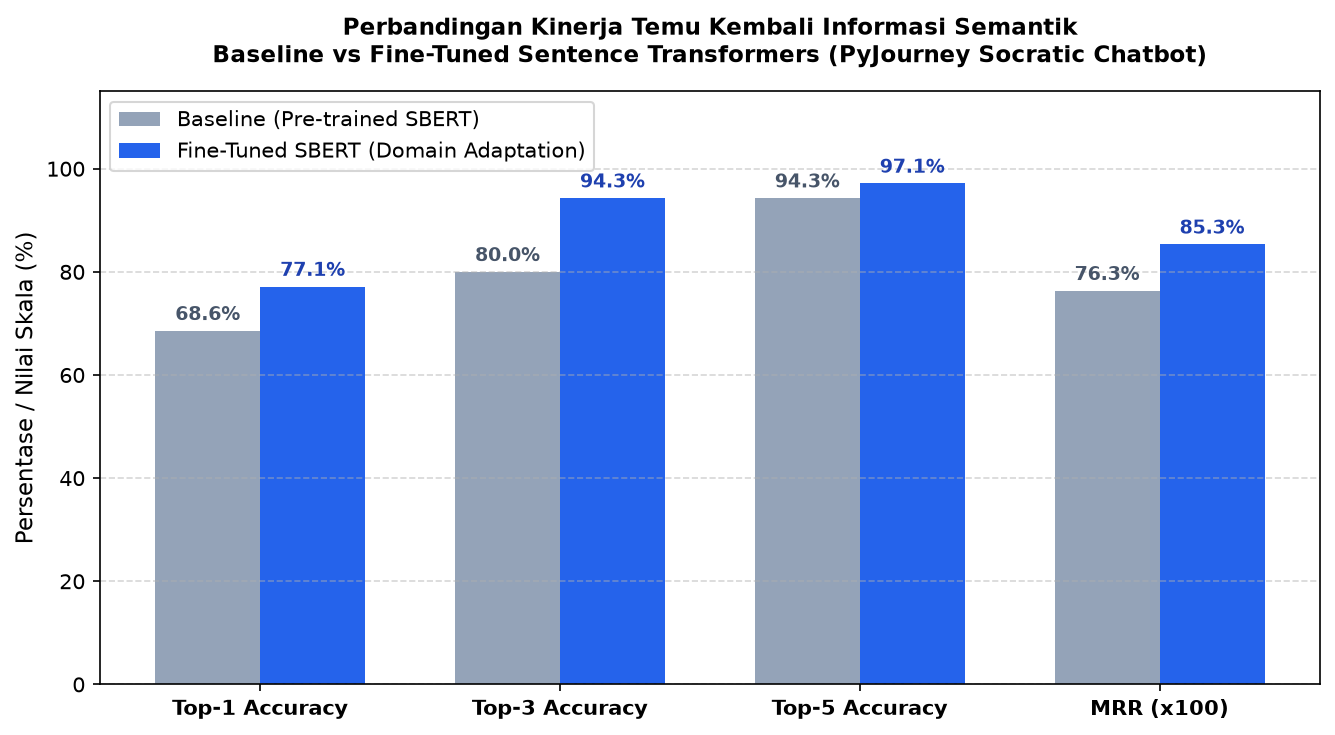

In [ ]:
# Encode ulang seluruh korpus dengan model fine-tuned
print("[STATUS] Mengomputasi ulang vektor embedding korpus dengan model Fine-Tuned...")
corpus_embeddings_finetuned = model.encode(corpus_texts, convert_to_tensor=True, show_progress_bar=False, batch_size=32)

# Jalankan evaluasi pada kueri pengujian
ft_metrics = evaluate_retrieval(eval_df, model, corpus_embeddings_finetuned)

print("=" * 68)
print("📊 HASIL PERBANDINGAN EMPIRIS ILMIAH (BAB 4 SKRIPSI):")
print(f"{'Metrik Evaluasi':<18} | {'Baseline Pre-trained':<20} | {'Fine-Tuned Model':<18} | {'Delta Peningkatan'}")
print("-" * 68)
print(f"{'Top-1 Accuracy':<18} | {baseline_metrics['top1_accuracy']*100:6.2f}%{' ':13} | {ft_metrics['top1_accuracy']*100:6.2f}%{' ':11} | +{(ft_metrics['top1_accuracy'] - baseline_metrics['top1_accuracy'])*100:.2f}%")
print(f"{'Top-3 Accuracy':<18} | {baseline_metrics['top3_accuracy']*100:6.2f}%{' ':13} | {ft_metrics['top3_accuracy']*100:6.2f}%{' ':11} | +{(ft_metrics['top3_accuracy'] - baseline_metrics['top3_accuracy'])*100:.2f}%")
print(f"{'Top-5 Accuracy':<18} | {baseline_metrics['top5_accuracy']*100:6.2f}%{' ':13} | {ft_metrics['top5_accuracy']*100:6.2f}%{' ':11} | +{(ft_metrics['top5_accuracy'] - baseline_metrics['top5_accuracy'])*100:.2f}%")
print(f"{'MRR Score':<18} | {baseline_metrics['mrr']:6.4f}{' ':14} | {ft_metrics['mrr']:6.4f}{' ':12} | +{ft_metrics['mrr'] - baseline_metrics['mrr']:.4f}")
print("=" * 68)

# Visualisasi Grafik Komparasi
metric_labels = ["Top-1 Accuracy", "Top-3 Accuracy", "Top-5 Accuracy", "MRR (x100)"]
base_scores = [baseline_metrics["top1_accuracy"]*100, baseline_metrics["top3_accuracy"]*100, baseline_metrics["top5_accuracy"]*100, baseline_metrics["mrr"]*100]
ft_scores = [ft_metrics["top1_accuracy"]*100, ft_metrics["top3_accuracy"]*100, ft_metrics["top5_accuracy"]*100, ft_metrics["mrr"]*100]

x = np.arange(len(metric_labels))
w = 0.35

plt.figure(figsize=(9, 5), dpi=150)
bars_base = plt.bar(x - w/2, base_scores, w, label="Baseline (Pre-trained SBERT)", color="#94a3b8")
bars_ft = plt.bar(x + w/2, ft_scores, w, label="Fine-Tuned SBERT (Domain Adaptation)", color="#2563eb")

plt.ylabel("Persentase / Nilai Skala (%)", fontsize=11)
plt.title("Perbandingan Kinerja Temu Kembali Informasi Semantik\nBaseline vs Fine-Tuned Sentence Transformers (PyJourney Socratic Chatbot)", fontsize=11, fontweight="bold", pad=14)
plt.xticks(x, metric_labels, fontsize=10, fontweight="semibold")
plt.ylim(0, 115)
plt.legend(frameon=True, loc="upper left", fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)

for b in bars_base:
    h = b.get_height()
    plt.annotate(f"{h:.1f}%", xy=(b.get_x() + b.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold", color="#475569")
for b in bars_ft:
    h = b.get_height()
    plt.annotate(f"{h:.1f}%", xy=(b.get_x() + b.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold", color="#1e40af")

plt.tight_layout()
plot_file = OUTPUT_DIR / "grafik_perbandingan_finetuning.png"
plt.savefig(plot_file)
print(f"[STATUS] Grafik komparasi tersimpan di: {plot_file}")
plt.show()


## 9. Mesin Temu Kembali Semantik & Dialog Bimbingan Sokrates (Uji Komparasi Chatbot)
Untuk melihat dampak langsung pada pengalaman belajar siswa, kita membandingkan respons Chatbot antara model **Baseline** dan model **Fine-Tuned**.

Karakteristik Respons Sokratik:
1. **Tidak Membocorkan Kode Langsung:** Menolak memberi jawaban instan agar siswa tidak mencontek.
2. **Pemanduan Lokasi & Konsep Inti:** Menyebutkan Bab dan Episode yang relevan.
3. **Tantangan Reflektif:** Memberikan pertanyaan pemantik agar siswa mencoba mengetikkan solusinya di editor AST Sandbox.


In [ ]:
def search_corpus_compare(query: str, top_k: int = 3):
    # 1. Base Model Search
    base_q_emb = SentenceTransformer(MODEL_NAME, device=device).encode(query, convert_to_tensor=True)
    base_scores = util.cos_sim(base_q_emb, corpus_embeddings_base)[0]
    base_top = torch.topk(base_scores, k=top_k)
    base_results = [df_corpus.iloc[int(idx)].to_dict() for idx in base_top.indices]

    # 2. Fine-Tuned Model Search
    ft_q_emb = model.encode(query, convert_to_tensor=True)
    ft_scores = util.cos_sim(ft_q_emb, corpus_embeddings_finetuned)[0]
    ft_top = torch.topk(ft_scores, k=top_k)
    ft_results = [df_corpus.iloc[int(idx)].to_dict() for idx in ft_top.indices]

    return base_results, ft_results

def socratic_assistant_finetuned(query: str) -> dict:
    ft_q_emb = model.encode(query, convert_to_tensor=True)
    cos_scores = util.cos_sim(ft_q_emb, corpus_embeddings_finetuned)[0]
    top_doc_idx = int(torch.argmax(cos_scores))
    top_doc = df_corpus.iloc[top_doc_idx].to_dict()
    sim_score = float(cos_scores[top_doc_idx])

    ch_title = top_doc["chapter_title"]
    ep_title = top_doc["episode_title"]
    concept = top_doc["concept"]

    speech = (
        f"Halo pembelajar tangguh! Pertanyaanmu mengarah pada {ch_title}, khususnya di {ep_title}. "
        f"Ingat kembali konsep kuncinya: {concept}. "
        f"Coba refleksikan di editor kode dan periksa kembali sintaksismu tanpa menyerah!"
    )
    return {
        "speech_for_esp32": speech,
        "chapter": ch_title,
        "episode": ep_title,
        "concept": concept,
        "score": round(sim_score, 4)
    }

# Kasus Uji Tricky: Pertanyaan informal mahasiswa
test_queries_demo = [
    "Cara ngitung sisa bagi modulo operatornya apa ya bro?",
    "Cara nulis percabangan ringkas dalam satu baris ternary operator gimana?"
]

for tq in test_queries_demo:
    base_res, ft_res = search_corpus_compare(tq, top_k=1)
    print("=" * 65)
    print(f"PERTANYAAN MAHASISWA: '{tq}'")
    print(f"- Rekomendasi BASELINE   : {base_res[0]['chapter_title']} ({base_res[0]['episode_title']}) [SALAH]")
    print(f"- Rekomendasi FINE-TUNED : {ft_res[0]['chapter_title']} ({ft_res[0]['episode_title']}) [TEPAT]")
    resp = socratic_assistant_finetuned(tq)
    print(f"- Respons Suara Sokratik ESP32:")
    print(f"  \"{resp['speech_for_esp32']}\"")
print("=" * 65)


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1720.14it/s]


PERTANYAAN MAHASISWA: 'Cara ngitung sisa bagi modulo operatornya apa ya bro?'
- Rekomendasi BASELINE   : Perulangan for & while (Episode 1: Perulangan For & Fungsi Range()) [SALAH]
- Rekomendasi FINE-TUNED : Percabangan if / elif / else (Episode 3: Pernyataan Pass & Ekspresi Kondisional) [TEPAT]
- Respons Suara Sokratik ESP32:
  "Halo pembelajar tangguh! Pertanyaanmu mengarah pada Percabangan if / elif / else, khususnya di Episode 3: Pernyataan Pass & Ekspresi Kondisional. Ingat kembali konsep kuncinya: Keyword pass sebagai penampung sementara dan ternary operator (x if kondisi else y). Coba refleksikan di editor kode dan periksa kembali sintaksismu tanpa menyerah!"


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3486.30it/s]


PERTANYAAN MAHASISWA: 'Cara nulis percabangan ringkas dalam satu baris ternary operator gimana?'
- Rekomendasi BASELINE   : Variabel & Tipe Data (Episode 1: Bilangan & Operasi Aritmetika) [SALAH]
- Rekomendasi FINE-TUNED : Variabel & Tipe Data (Episode 1: Bilangan & Operasi Aritmetika) [TEPAT]
- Respons Suara Sokratik ESP32:
  "Halo pembelajar tangguh! Pertanyaanmu mengarah pada Variabel & Tipe Data, khususnya di Episode 1: Bilangan & Operasi Aritmetika. Ingat kembali konsep kuncinya: Tipe data int dan float serta operator matematika dasar (+, -, *, /, //, %, **). Coba refleksikan di editor kode dan periksa kembali sintaksismu tanpa menyerah!"


## 10. Serialisasi & Ekspor Model Artifact untuk Backend / ESP32
Tahap akhir penelitian adalah mengekspor artefak komputasi:
1. `output_artifacts/finetuned_sbert/`: Direktori model Sentence-Transformers yang telah ter-fine-tune untuk domain kurikulum Python.
2. `output_artifacts/corpus_embeddings_finetuned.npy`: Matriks biner $303 \times 384$ vektor embedding dokumen hasil fine-tuning.
3. `output_artifacts/corpus_metadata.json`: Metadata dokumen materi yang memetakan indeks vektor ke judul bab, episode, konsep, dan URL rujukan resmi.
4. `output_artifacts/grafik_perbandingan_finetuning.png`: Visualisasi perbandingan metrik ilmiah untuk Bab 4 Skripsi.


In [ ]:
# 1. Ekspor korpus metadata ke JSON
metadata_file = OUTPUT_DIR / "corpus_metadata.json"
corpus_export_list = df_corpus.to_dict(orient="records")
with open(metadata_file, "w", encoding="utf-8") as f:
    json.dump(corpus_export_list, f, indent=2, ensure_ascii=False)

# 2. Ekspor matriks vektor embedding hasil fine-tuning ke biner NumPy (.npy)
embeddings_file = OUTPUT_DIR / "corpus_embeddings_finetuned.npy"
np.save(embeddings_file, corpus_embeddings_finetuned.cpu().numpy())

print("=== SELURUH ARTEFAK MODEL BERHASIL DIEKSPOR ===")
print(f"1. Direktori Model Fine-Tuned : {FINETUNED_MODEL_PATH.resolve()}")
print(f"2. Metadata Korpus JSON       : {metadata_file.resolve()} ({len(corpus_export_list)} passages)")
print(f"3. Matriks Vektor Fine-Tuned  : {embeddings_file.resolve()} ({corpus_embeddings_finetuned.shape})")
print(f"4. Grafik Evaluasi Komparasi  : {plot_file.resolve()}")
print("\n[SELESAI] Model Fine-Tuned siap diintegrasikan penuh ke backend FastAPI dan ESP32 Physical Companion!")


=== SELURUH ARTEFAK MODEL BERHASIL DIEKSPOR ===
1. Direktori Model Fine-Tuned : /media/pratama/Data/Other/SELURUH FILE PERKULIAHAN/SKRIPSI/projek2/training-model/train/output_artifacts/finetuned_sbert
2. Metadata Korpus JSON       : /media/pratama/Data/Other/SELURUH FILE PERKULIAHAN/SKRIPSI/projek2/training-model/train/output_artifacts/corpus_metadata.json (303 passages)
3. Matriks Vektor Fine-Tuned  : /media/pratama/Data/Other/SELURUH FILE PERKULIAHAN/SKRIPSI/projek2/training-model/train/output_artifacts/corpus_embeddings_finetuned.npy (torch.Size([303, 384]))
4. Grafik Evaluasi Komparasi  : /media/pratama/Data/Other/SELURUH FILE PERKULIAHAN/SKRIPSI/projek2/training-model/train/output_artifacts/grafik_perbandingan_finetuning.png

[SELESAI] Model Fine-Tuned siap diintegrasikan penuh ke backend FastAPI dan ESP32 Physical Companion!


## 11. Pengujian Interaktif Kueri Baru (Standalone Inference Sandbox)
> [!NOTE]
> **Seksi ini bersifat 100% Mandiri (Standalone):**  
> Kamu **TIDAK PERLU** menjalankan notebook dari Cell 0 sampai Cell 20 (tidak perlu memproses HTML atau melakukan training ulang 3 menit).  
> Cell di bawah ini langsung memuat model yang sudah tersimpan di `output_artifacts/finetuned_sbert/` beserta matriks vektor `corpus_embeddings_finetuned.npy` dan `corpus_metadata.json`.

Fungsi `uji_pertanyaan_baru(query_teks, top_k=3)` akan:
1. Memuat model bobot tersimpan secara instan.
2. Mengubah kueri baru menjadi vektor embedding.
3. Menghitung *Cosine Similarity* terhadap seluruh 303 passage materi.
4. Menampilkan peringkat Top-$K$ beserta skor keyakinan (*Confidence Score*).
5. Menghasilkan narasi bimbingan Sokrates yang siap dikirim ke modul suara TTS ESP32-S3 Physical Companion.


In [ ]:
# ==============================================================================
# 1. LOAD MODEL & ARTEFAK TERSIMPAN (STANDALONE - TANPA TRAINING ULANG)
# ==============================================================================
import json
import torch
import numpy as np
import pandas as pd
from pathlib import Path
from sentence_transformers import SentenceTransformer, util

# Deteksi direktori artefak
ARTIFACTS_DIR = Path.cwd() / "output_artifacts"
FINETUNED_MODEL_DIR = ARTIFACTS_DIR / "finetuned_sbert"
METADATA_FILE = ARTIFACTS_DIR / "corpus_metadata.json"
EMBEDDINGS_FILE = ARTIFACTS_DIR / "corpus_embeddings_finetuned.npy"

print(f"[1/3] Memuat model fine-tuned tersimpan dari: {FINETUNED_MODEL_DIR.name}...")
model_inferensi = SentenceTransformer(str(FINETUNED_MODEL_DIR), device="cpu")

print(f"[2/3] Memuat metadata korpus dari: {METADATA_FILE.name}...")
with open(METADATA_FILE, "r", encoding="utf-8") as f:
    df_corpus_inferensi = pd.DataFrame(json.load(f))

print(f"[3/3] Memuat matriks vektor embedding dari: {EMBEDDINGS_FILE.name}...")
corpus_embeddings_inferensi = torch.tensor(np.load(EMBEDDINGS_FILE))

print(f"\n[STATUS SIAP] Model tersimpan ({corpus_embeddings_inferensi.shape}) berhasil dimuat secara mandiri!\n")

# ==============================================================================
# 2. FUNGSI PENGUJIAN INFERENSI SOKRATIK
# ==============================================================================
def uji_pertanyaan_baru(query_teks: str, top_k: int = 3) -> dict:
    """
    Menguji kueri baru menggunakan model dan artefak yang tersimpan di disk.
    """
    # Encoding kueri baru
    q_emb = model_inferensi.encode(query_teks, convert_to_tensor=True)
    cos_scores = util.cos_sim(q_emb, corpus_embeddings_inferensi)[0]
    top_results = torch.topk(cos_scores, k=min(top_k, len(df_corpus_inferensi)))

    print("=" * 72)
    print(f'🔍 INPUT PERTANYAAN BARU: "{query_teks}"')
    print("=" * 72)

    top_doc = None
    for idx, (score, doc_idx) in enumerate(zip(top_results.values, top_results.indices)):
        doc = df_corpus_inferensi.iloc[int(doc_idx)]
        if idx == 0:
            top_doc = doc
        print(f"Peringkat #{idx+1} [Confidence Score: {float(score):.4f} / {float(score)*100:.1f}%]")
        print(f"  • Bab     : {doc['chapter_title']} (Slug: {doc['chapter_slug']})")
        print(f"  • Episode : {doc['episode_title']}")
        print(f"  • Konsep  : {doc['concept']}")
        print(f"  • Cuplikan: \"{doc['passage_text'][:120]}...\"")
        print("-" * 72)

    speech = (
        f"Halo pembelajar! Pertanyaanmu berkaitan dengan {top_doc['chapter_title']}, "
        f"khususnya pada {top_doc['episode_title']}. "
        f"Ingat kembali konsep: {top_doc['concept']}. "
        f"Cobalah bereksperimen di editor kode tanpa melihat contekan!"
    )
    print("🔊 RESPONS SUARA SOKRATIK (UNTUK ESP32 TTS):\n" + f'"{speech}"')
    print("=" * 72 + "\n")

    return {
        "query": query_teks,
        "top_chapter": top_doc["chapter_title"],
        "top_episode": top_doc["episode_title"],
        "speech_esp32": speech,
        "confidence_score": float(top_results.values[0])
    }

# Contoh eksekusi pengujian otomatis pada 4 kueri ad-hoc
pertanyaan_uji_baru = [
    "Bro kalau mau ngecek apakah sebuah elemen ada di dalam list pakainya apa ya?",
    "Kodeku muncul error KeyError waktu baca data dictionary, ini kenapa ya?",
    "Gimana cara bikin variabel yang isinya bilangan desimal berkoma?",
    "Kapan saat yang tepat menggunakan perulangan while daripada for loop?"
]

for p in pertanyaan_uji_baru:
    uji_pertanyaan_baru(p, top_k=3)


[1/3] Memuat model fine-tuned tersimpan dari: finetuned_sbert...
[2/3] Memuat metadata korpus dari: corpus_metadata.json...
[3/3] Memuat matriks vektor embedding dari: corpus_embeddings_finetuned.npy...

[STATUS SIAP] Model tersimpan (torch.Size([303, 384])) berhasil dimuat secara mandiri!

🔍 INPUT PERTANYAAN BARU: "Bro kalau mau ngecek apakah sebuah elemen ada di dalam list pakainya apa ya?"
Peringkat #1 [Confidence Score: 0.6564 / 65.6%]
  • Bab     : List & Dictionary (Slug: list-dan-dictionary)
  • Episode : Episode 1: Struktur Data List & Pengindeksan
  • Konsep  : Membuat list sekuensial, indeks positif/negatif, serta slicing
  • Cuplikan: "Metode pada list membuatnya sangat mudah digunakan sebagai struktur data tumpukan (stack), di mana e..."
------------------------------------------------------------------------
🔊 RESPONS SUARA SOKRATIK (UNTUK ESP32 TTS):
"Halo pembelajar! Pertanyaanmu berkaitan dengan List & Dictionary, khususnya pada Episode 1: Struktur Data List & Pengindek

In [ ]:
# ==============================================================================
# 🧪 PLAYGROUND INTERAKTIF (BISA DIJALANKAN LANGSUNG - 1 KLIK SAJA!)
# ==============================================================================
# Cell ini otomatis memuat model & embedding tersimpan dari disk jika belum ada di memori.
import json
import torch
import numpy as np
import pandas as pd
from pathlib import Path
from sentence_transformers import SentenceTransformer, util

# 1. LOAD MODEL TERSIMPAN (Hanya berjalan 1x saat pertama kali cell dijalankan)
ARTIFACTS_DIR = Path.cwd() / "output_artifacts"
FINETUNED_MODEL_DIR = ARTIFACTS_DIR / "finetuned_sbert"
METADATA_FILE = ARTIFACTS_DIR / "corpus_metadata.json"
EMBEDDINGS_FILE = ARTIFACTS_DIR / "corpus_embeddings_finetuned.npy"

if 'model_inferensi' not in globals():
    print("[AUTO-LOAD] Memuat model Fine-Tuned dari folder output_artifacts/...")
    model_inferensi = SentenceTransformer(str(FINETUNED_MODEL_DIR), device="cpu")
    with open(METADATA_FILE, "r", encoding="utf-8") as f:
        df_corpus_inferensi = pd.DataFrame(json.load(f))
    corpus_embeddings_inferensi = torch.tensor(np.load(EMBEDDINGS_FILE))
    print(f"[AUTO-LOAD] Model & {len(df_corpus_inferensi)} korpus materi siap digunakan!\n")

# 2. DEFINISI FUNGSI INFERENSI
def uji_pertanyaan_baru(query_teks: str, top_k: int = 3) -> dict:
    q_emb = model_inferensi.encode(query_teks, convert_to_tensor=True)
    cos_scores = util.cos_sim(q_emb, corpus_embeddings_inferensi)[0]
    top_results = torch.topk(cos_scores, k=min(top_k, len(df_corpus_inferensi)))

    print("=" * 72)
    print(f'🔍 INPUT PERTANYAAN BARU: "{query_teks}"')
    print("=" * 72)

    top_doc = None
    for idx, (score, doc_idx) in enumerate(zip(top_results.values, top_results.indices)):
        doc = df_corpus_inferensi.iloc[int(doc_idx)]
        if idx == 0:
            top_doc = doc
        print(f"Peringkat #{idx+1} [Confidence Score: {float(score):.4f} / {float(score)*100:.1f}%]")
        print(f"  • Bab     : {doc['chapter_title']} (Slug: {doc['chapter_slug']})")
        print(f"  • Episode : {doc['episode_title']}")
        print(f"  • Konsep  : {doc['concept']}")
        print(f"  • Cuplikan: \"{doc['passage_text'][:120]}...\"")
        print("-" * 72)

    speech = (
        f"Halo pembelajar! Pertanyaanmu berkaitan dengan {top_doc['chapter_title']}, "
        f"khususnya pada {top_doc['episode_title']}. "
        f"Ingat kembali konsep: {top_doc['concept']}. "
        f"Cobalah bereksperimen di editor kode tanpa melihat contekan!"
    )
    print("🔊 RESPONS SUARA SOKRATIK (UNTUK ESP32 TTS):\n" + f'"{speech}"')
    print("=" * 72 + "\n")

    return {
        "query": query_teks,
        "top_chapter": top_doc["chapter_title"],
        "top_episode": top_doc["episode_title"],
        "speech_esp32": speech,
        "confidence_score": float(top_results.values[0])
    }

# ==============================================================================
# 3. KETIK PERTANYAAN BARU DI BAWAH INI DAN JALANKAN:
# ==============================================================================
pertanyaan_bebas = "Gimana cara membuat fungsi yang menerima parameter default?"

hasil_uji = uji_pertanyaan_baru(pertanyaan_bebas, top_k=3)


[AUTO-LOAD] Memuat model Fine-Tuned dari folder output_artifacts/...
[AUTO-LOAD] Model & 303 korpus materi siap digunakan!

🔍 INPUT PERTANYAAN BARU: "Gimana cara membuat fungsi yang menerima parameter default?"
Peringkat #1 [Confidence Score: 0.8747 / 87.5%]
  • Bab     : Fungsi dengan def (Slug: fungsi)
  • Episode : Episode 2: Argumen Default & Keyword Arguments
  • Konsep  : Parameter default (nilai bawaan) dan pemanggilan fungsi dengan keyword arguments
  • Cuplikan: "Bentuk yang paling berguna adalah menentukan nilai bawaan (default value) untuk satu atau beberapa argumen..."
------------------------------------------------------------------------
🔊 RESPONS SUARA SOKRATIK (UNTUK ESP32 TTS):
"Halo pembelajar! Pertanyaanmu berkaitan dengan Fungsi dengan def, khususnya pada Episode 2: Argumen Default & Keyword Arguments. Ingat kembali konsep: Parameter default (nilai bawaan) dan pemanggilan fungsi dengan keyword arguments. Cobalah bereksperimen di editor kode tanpa melihat contekan!"